# SepsisShield — Person 3: Temporal Feature Engineering, Feature Selection and PCA

**Purpose:** Transform patient-wise clinical histories into meaningful temporal features, investigate feature quality, explore PCA and prepare a patient-separated validation manifest.

**Input:** `outputs/02_preprocessing/cleaned_dataset.csv.gz` created by Person 2.

**Outputs:** `outputs/03_feature_engineering/feature_engineered_dataset.csv.gz`, feature dictionary, feature-quality/correlation/MI/PCA reports and patient split manifest.

> This notebook performs feature engineering and exploratory feature analysis. It does not train or claim a clinically validated sepsis prediction model. The original PhysioNet `SepsisLabel` already begins up to six hours before challenge-defined sepsis onset; do not shift it again.

## 1. Imports and input selection

The notebook requires Person 2's cleaned dataset. It falls back to the original CSV only if the cleaned file does not yet exist, and clearly reports which input was used.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif


from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the project root whether Jupyter starts in the project root or notebooks/.
_SEARCH_BASES = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = None
for _base in _SEARCH_BASES:
    if (_base / "data" / "Dataset.csv").is_file():
        PROJECT_ROOT = _base
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate project root. Expected data/Dataset.csv beneath the current folder. "
        f"Current directory: {Path.cwd().resolve()}"
    )

DATA_PATH = PROJECT_ROOT / "data" / "Dataset.csv"
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
REPORT_ROOT = PROJECT_ROOT / "reports"
OUTPUT_ROOT.mkdir(exist_ok=True)
REPORT_ROOT.mkdir(exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Original dataset:", DATA_PATH)
print("Dataset exists:", DATA_PATH.is_file())

FE_DIR = OUTPUT_ROOT / "03_feature_engineering"
FIG_DIR = FE_DIR / "figures"
FE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_PATH = OUTPUT_ROOT / "02_preprocessing" / "cleaned_dataset.csv.gz"
if CLEAN_PATH.is_file():
    INPUT_PATH = CLEAN_PATH
    INPUT_COMPRESSION = "gzip"
else:
    INPUT_PATH = DATA_PATH
    INPUT_COMPRESSION = "infer"
    print("WARNING: Person 2 output not found. Falling back to the original CSV.")
print("Feature-engineering input:", INPUT_PATH)

Project root: /Users/mohammedfaisalpasha/Downloads/SepsisShield_NIErnaya_Phase2
Original dataset: /Users/mohammedfaisalpasha/Downloads/SepsisShield_NIErnaya_Phase2/data/Dataset.csv
Dataset exists: True
Feature-engineering input: /Users/mohammedfaisalpasha/Downloads/SepsisShield_NIErnaya_Phase2/outputs/02_preprocessing/cleaned_dataset.csv.gz


## 2. Load and validate the working dataset

In [5]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path.home() / "Downloads" / "SepsisShield_NIErnaya_Phase2"

SOURCE_PATH = BASE_DIR / "data" / "Dataset.csv"
OUTPUT_PATH = BASE_DIR / "outputs" / "02_preprocessing" / "cleaned_dataset.csv.gz"

# Check that the original dataset exists
if not SOURCE_PATH.exists():
    raise FileNotFoundError(f"Original dataset not found: {SOURCE_PATH}")

print("Loading original dataset...")
df = pd.read_csv(SOURCE_PATH, low_memory=False)

# Remove the redundant index column only if it exactly matches Hour
if "Unnamed: 0" in df.columns and df["Unnamed: 0"].equals(df["Hour"]):
    df = df.drop(columns=["Unnamed: 0"])

# Sort records chronologically within each patient
df = df.sort_values(
    ["Patient_ID", "Hour"],
    kind="mergesort"
).reset_index(drop=True)

# Save a fresh gzip file
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(
    OUTPUT_PATH,
    index=False,
    compression="gzip"
)

print("New cleaned dataset created successfully!")
print("Shape:", df.shape)
print("Saved at:", OUTPUT_PATH)

Loading original dataset...
New cleaned dataset created successfully!
Shape: (1552210, 43)
Saved at: /Users/mohammedfaisalpasha/Downloads/SepsisShield_NIErnaya_Phase2/outputs/02_preprocessing/cleaned_dataset.csv.gz


## 3. Select vital signs for temporal feature engineering

The current project implementation starts with seven commonly monitored vital signs. The other laboratory and contextual variables remain available for exploratory feature-selection analysis, but are not given lag/rolling features in this first pass.

In [6]:
CANDIDATE_VITALS = ["HR","O2Sat","Temp","MAP","SBP","DBP","Resp"]
VITALS = [c for c in CANDIDATE_VITALS if c in df.columns]
if len(VITALS) != len(CANDIDATE_VITALS):
    raise ValueError(f"Expected all seven vital signs. Found: {VITALS}")
print("Selected vital signs:",VITALS)

Selected vital signs: ['HR', 'O2Sat', 'Temp', 'MAP', 'SBP', 'DBP', 'Resp']


## 4. Verify the patient-time structure

`Hour` is the zero-based within-patient observation index in this merged CSV; `ICULOS` is the ICU length-of-stay field. They are not interchangeable. Check patient-hour uniqueness and consecutive `Hour` steps before making windows.

In [7]:
duplicate_keys = int(df.duplicated(["Patient_ID","Hour"]).sum())
hour_diff = df.groupby("Patient_ID",sort=False)["Hour"].diff()
nonconsecutive_gaps = int((hour_diff.notna() & hour_diff.ne(1)).sum())
print("Duplicate patient-hour keys:",duplicate_keys)
print("Non-consecutive Hour gaps:",nonconsecutive_gaps)
if duplicate_keys:
    raise ValueError("Resolve duplicate patient-hour keys before feature engineering.")

Duplicate patient-hour keys: 0
Non-consecutive Hour gaps: 0


## 5. Create temporal features — core implementation

For each of the seven vital signs, create exactly eight derived features:

1. lag 1; 2. lag 3; 3. change from previous hour; 4. rolling mean 3; 5. rolling mean 6; 6. rolling standard deviation 6; 7. missing now; 8. missing count in the latest 6 consecutive observations.

All calculations are performed within each patient. The current and previous observations may be used; future observations are never used. Rolling windows are masked unless the required time span is consecutive.

In [8]:
def add_temporal_features(data, vital_cols, patient_col="Patient_ID", time_col="Hour"):
    """Add patient-wise lag, change, rolling and missingness features."""
    out = data.sort_values([patient_col,time_col],kind="mergesort").reset_index(drop=True).copy()
    patient_groups = out.groupby(patient_col,sort=False)
    time_groups = out.groupby(patient_col,sort=False)[time_col]

    gap1 = time_groups.diff().eq(1)
    # A 3-record window has 2 consecutive gaps; a 6-record window has 5.
    consecutive_3 = (gap1.groupby(out[patient_col],sort=False)
                     .rolling(2,min_periods=2).sum()
                     .reset_index(level=0,drop=True).eq(2))
    consecutive_6 = (gap1.groupby(out[patient_col],sort=False)
                     .rolling(5,min_periods=5).sum()
                     .reset_index(level=0,drop=True).eq(5))
    hour_diff_3 = time_groups.diff(3).eq(3)

    for col in vital_cols:
        values = out.groupby(patient_col,sort=False)[col]
        lag1 = values.shift(1).where(gap1)
        lag3 = values.shift(3).where(hour_diff_3)
        out[f"{col}_lag_1"] = lag1
        out[f"{col}_lag_3"] = lag3
        out[f"{col}_change_1"] = out[col] - lag1

        roll3 = (values.rolling(3,min_periods=2).mean()
                 .reset_index(level=0,drop=True))
        roll6 = (values.rolling(6,min_periods=3).mean()
                 .reset_index(level=0,drop=True))
        std6 = (values.rolling(6,min_periods=3).std()
                .reset_index(level=0,drop=True))
        out[f"{col}_roll_mean_3"] = roll3.where(consecutive_3)
        out[f"{col}_roll_mean_6"] = roll6.where(consecutive_6)
        out[f"{col}_roll_std_6"] = std6.where(consecutive_6)

        missing_now = out[col].isna().astype("int8")
        out[f"{col}_missing_now"] = missing_now
        missing6 = (missing_now.groupby(out[patient_col],sort=False)
                    .rolling(6,min_periods=6).sum()
                    .reset_index(level=0,drop=True))
        out[f"{col}_missing_count_6"] = missing6.where(consecutive_6)

    return out

original_shape = df.shape
original_columns = set(df.columns)
TARGET_CHECK = df[["Patient_ID","Hour","SepsisLabel"]].copy()
df_features = add_temporal_features(df,VITALS)
new_feature_columns = [c for c in df_features.columns if c not in original_columns]
print("Original shape:",original_shape)
print("Engineered shape:",df_features.shape)
print("New feature count:",len(new_feature_columns))
print("Expected new feature count:",len(VITALS)*8)
assert len(new_feature_columns) == len(VITALS)*8

Original shape: (1552210, 43)
Engineered shape: (1552210, 99)
New feature count: 56
Expected new feature count: 56


## 6. Inspect feature values on real rows

Use these records to check that a lag is from the same patient and an earlier hour. These values are taken from the actual CSV loaded above.

In [9]:
sample_patient = df_features["Patient_ID"].iloc[0]
show_cols = ["Patient_ID","Hour","ICULOS","SepsisLabel"] + VITALS[:3]
show_cols += [c for c in [f"{VITALS[0]}_lag_1",f"{VITALS[0]}_lag_3",f"{VITALS[0]}_change_1",f"{VITALS[0]}_roll_mean_3",f"{VITALS[0]}_roll_mean_6",f"{VITALS[0]}_roll_std_6",f"{VITALS[0]}_missing_now",f"{VITALS[0]}_missing_count_6"] if c in df_features.columns]
display(df_features.loc[df_features.Patient_ID.eq(sample_patient),show_cols].head(15))

,Patient_ID,Hour,ICULOS,SepsisLabel,HR,O2Sat,Temp,HR_lag_1,HR_lag_3,HR_change_1,HR_roll_mean_3,HR_roll_mean_6,HR_roll_std_6,HR_missing_now,HR_missing_count_6
0,1,0,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN
1,1,1,2,0,97.0,95.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
2,1,2,3,0,89.0,99.0,NaN,97.0,NaN,-8.0,93.000000,NaN,NaN,0,NaN
3,1,3,4,0,90.0,95.0,NaN,89.0,NaN,1.0,92.000000,NaN,NaN,0,NaN
4,1,4,5,0,103.0,88.5,NaN,90.0,97.0,13.0,94.000000,NaN,NaN,0,NaN
5,1,5,6,0,110.0,91.0,NaN,103.0,89.0,7.0,101.000000,97.800000,8.871302,0,1.0
6,1,6,7,0,108.0,92.0,36.11,110.0,90.0,-2.0,107.000000,99.500000,8.961027,0,0.0
7,1,7,8,0,106.0,90.5,NaN,108.0,103.0,-2.0,108.000000,101.000000,9.208692,0,0.0
8,1,8,9,0,104.0,95.0,NaN,106.0,110.0,-2.0,106.000000,103.500000,7.092249,0,0.0
9,1,9,10,0,102.0,91.0,NaN,104.0,108.0,-2.0,104.000000,105.500000,3.082207,0,0.0


## 7. Validate patient boundaries, time windows and target preservation

In [10]:
first_rows = df_features.groupby("Patient_ID",sort=False).head(1)
lag1_cols = [f"{c}_lag_1" for c in VITALS]
nonmissing_first_lags = int(first_rows[lag1_cols].notna().sum().sum())
assert first_rows[lag1_cols].isna().all().all(), "Lag values crossed patient boundaries."

# Compare target values and row identity before/after feature generation.
check_after = df_features[["Patient_ID","Hour","SepsisLabel"]]
assert TARGET_CHECK.reset_index(drop=True).equals(check_after.reset_index(drop=True)), "Target or patient-hour row alignment changed."

numeric_new = df_features[new_feature_columns].select_dtypes(include=np.number)
infinite_count = int(np.isinf(numeric_new.to_numpy()).sum())
assert infinite_count == 0, "Infinite values found in engineered features."

print("First-row non-missing lag values:",nonmissing_first_lags)
print("Target and row alignment preserved: True")
print("Infinite engineered values:",infinite_count)
print("Patient-boundary checks passed.")

First-row non-missing lag values: 0
Target and row alignment preserved: True
Infinite engineered values: 0
Patient-boundary checks passed.


## 8. Feature dictionary

In [11]:
feature_definitions = {
    "lag_1":"Value from the previous consecutive Hour for the same patient.",
    "lag_3":"Value from three Hours earlier for the same patient, requiring the three-hour span.",
    "change_1":"Current value minus previous consecutive-hour value.",
    "roll_mean_3":"Mean of current and previous two consecutive observations; at least two non-missing values.",
    "roll_mean_6":"Mean of current and previous five consecutive observations; at least three non-missing values.",
    "roll_std_6":"Sample standard deviation across current and previous five consecutive observations; at least three non-missing values.",
    "missing_now":"1 if the current measurement is missing, otherwise 0.",
    "missing_count_6":"Number of missing measurements in current and previous five consecutive observations; NaN if window is not consecutive."
}
feature_dictionary=[]
for vital in VITALS:
    for suffix,definition in feature_definitions.items():
        feature_dictionary.append({"feature":f"{vital}_{suffix}","source_variable":vital,
                                   "feature_type":suffix,"definition":definition,
                                   "uses_future_data":False,"computed_within_patient":True})
feature_dictionary=pd.DataFrame(feature_dictionary)
feature_dictionary.to_csv(FE_DIR/"feature_dictionary.csv",index=False)
display(feature_dictionary)

,feature,source_variable,feature_type,definition,uses_future_data,computed_within_patient
0,HR_lag_1,HR,lag_1,Value from the previous consecutive Hour for t...,False,True
1,HR_lag_3,HR,lag_3,Value from three Hours earlier for the same pa...,False,True
2,HR_change_1,HR,change_1,Current value minus previous consecutive-hour ...,False,True
3,HR_roll_mean_3,HR,roll_mean_3,Mean of current and previous two consecutive o...,False,True
4,HR_roll_mean_6,HR,roll_mean_6,Mean of current and previous five consecutive ...,False,True
5,HR_roll_std_6,HR,roll_std_6,Sample standard deviation across current and p...,False,True
6,HR_missing_now,HR,missing_now,"1 if the current measurement is missing, other...",False,True
7,HR_missing_count_6,HR,missing_count_6,Number of missing measurements in current and ...,False,True
8,O2Sat_lag_1,O2Sat,lag_1,Value from the previous consecutive Hour for t...,False,True
9,O2Sat_lag_3,O2Sat,lag_3,Value from three Hours earlier for the same pa...,False,True


## 9. Create a patient-separated train/test manifest before feature selection

Stratify at patient level using whether each patient ever has a positive challenge label. This keeps every row from one patient in the same partition. The manifest is separate so `Patient_ID` is not accidentally used as a predictor.

In [12]:
from sklearn.model_selection import train_test_split
patient_outcome = df_features.groupby("Patient_ID")["SepsisLabel"].max().rename("any_positive_label").reset_index()
train_ids,test_ids = train_test_split(
    patient_outcome["Patient_ID"],test_size=0.20,random_state=42,
    stratify=patient_outcome["any_positive_label"]
)
train_ids=set(train_ids.tolist()); test_ids=set(test_ids.tolist())
assert train_ids.isdisjoint(test_ids)
assert len(train_ids)+len(test_ids)==df_features.Patient_ID.nunique()
train_mask=df_features.Patient_ID.isin(train_ids)
test_mask=df_features.Patient_ID.isin(test_ids)

manifest=patient_outcome.copy()
manifest["split"] = manifest["Patient_ID"].map(lambda x:"train" if x in train_ids else "test")
manifest.to_csv(FE_DIR/"patient_split_manifest.csv",index=False)
print("Training patients:",len(train_ids),"Test patients:",len(test_ids))
print("Training rows:",int(train_mask.sum()),"Test rows:",int(test_mask.sum()))
print("Training positive hourly-label rate:",round(df_features.loc[train_mask,"SepsisLabel"].mean()*100,3),"%")
print("Test positive hourly-label rate:",round(df_features.loc[test_mask,"SepsisLabel"].mean()*100,3),"%")

Training patients: 32268 Test patients: 8068
Training rows: 1240596 Test rows: 311614
Training positive hourly-label rate: 1.803 %
Test positive hourly-label rate: 1.782 %


## 10. Feature quality investigation (training patients only)

Report missingness, number of unique values and variance for candidate numeric predictors. This is an investigation report, not an automatic feature-deletion rule.

In [13]:
EXCLUDE_FROM_PREDICTORS={"Patient_ID","Hour","SepsisLabel","Unnamed: 0"}
predictor_columns=[c for c in df_features.select_dtypes(include=np.number).columns if c not in EXCLUDE_FROM_PREDICTORS]
train_sample=df_features.loc[train_mask,predictor_columns]
quality=pd.DataFrame({
    "missing_pct":train_sample.isna().mean()*100,
    "unique_values":train_sample.nunique(dropna=True),
    "variance":train_sample.var()
})
quality["all_missing_in_train"] = quality["unique_values"].eq(0)
quality["constant_in_train"] = quality["unique_values"].le(1)
quality=quality.sort_values(["missing_pct","variance"],ascending=[False,True])
quality.to_csv(FE_DIR/"feature_quality_training_only.csv")
display(quality.head(25))

,missing_pct,unique_values,variance,all_missing_in_train,constant_in_train
Bilirubin_direct,99.804932,256,13.583511,False,False
Fibrinogen,99.326856,791,23722.477805,False,False
TroponinI,99.046587,2143,545.751980,False,False
Bilirubin_total,98.502816,384,18.831194,False,False
Alkalinephos,98.387146,697,15027.326212,False,False
AST,98.370702,1856,794180.707650,False,False
Lactate,97.315806,1257,6.494545,False,False
PTT,97.023850,1345,673.250691,False,False
SaO2,96.516271,414,118.970079,False,False
EtCO2,96.273243,133,62.179117,False,False


## 11. Training-only correlation investigation

Use a reproducible sample of training rows to estimate Spearman correlations. High correlation suggests overlapping information, but does not automatically justify deleting a clinically meaningful feature.

In [14]:
CORR_SAMPLE_N=min(50_000,int(train_mask.sum()))
train_corr_sample=df_features.loc[train_mask,predictor_columns].sample(CORR_SAMPLE_N,random_state=42)
cor=train_corr_sample.corr(method="spearman",min_periods=500)
cor.to_csv(FE_DIR/"spearman_correlation_training_sample.csv")

upper=cor.where(np.triu(np.ones(cor.shape),k=1).astype(bool))
pairs=upper.stack().rename("spearman_corr").reset_index()
pairs.columns=["feature_1","feature_2","spearman_corr"]
pairs["abs_corr"]=pairs["spearman_corr"].abs()
high_pairs=pairs[pairs.abs_corr>=0.95].sort_values("abs_corr",ascending=False)
high_pairs.to_csv(FE_DIR/"high_correlation_pairs_training_only.csv",index=False)
print("High-correlation pairs at |rho| >= 0.95:",len(high_pairs))
display(high_pairs.head(30))

High-correlation pairs at |rho| >= 0.95: 13


,feature_1,feature_2,spearman_corr,abs_corr
2360,Unit1,Unit2,-1.000000,1.000000
3350,Temp_lag_1,Temp_roll_mean_3,0.985586,0.985586
2751,HR_roll_mean_3,HR_roll_mean_6,0.975351,0.975351
2592,HR_lag_1,HR_roll_mean_3,0.971595,0.971595
3389,Temp_lag_3,Temp_roll_mean_6,0.967002,0.967002
231,Temp,Temp_roll_mean_3,0.959753,0.959753
39,HR,HR_roll_mean_3,0.958416,0.958416
3461,Temp_roll_mean_3,Temp_roll_mean_6,0.956001,0.956001
4046,DBP_roll_mean_3,DBP_roll_mean_6,0.954457,0.954457
2647,HR_lag_3,HR_roll_mean_6,0.954167,0.954167


## 12. Mutual-information ranking — training-only, balanced exploratory sample

Mutual information estimates statistical dependence between a feature and the target. It does not establish causation and it is not a substitute for evaluating a trained model. Imputation and ranking are performed using training patients only.

,feature,mutual_information
38,HospAdmTime,0.119726
39,ICULOS,0.089869
34,Age,0.087585
0,HR,0.022091
89,Resp_lag_3,0.020253
7,EtCO2,0.020002
92,Resp_roll_mean_6,0.019855
91,Resp_roll_mean_3,0.017990
8,BaseExcess,0.016431
43,HR_roll_mean_3,0.016170


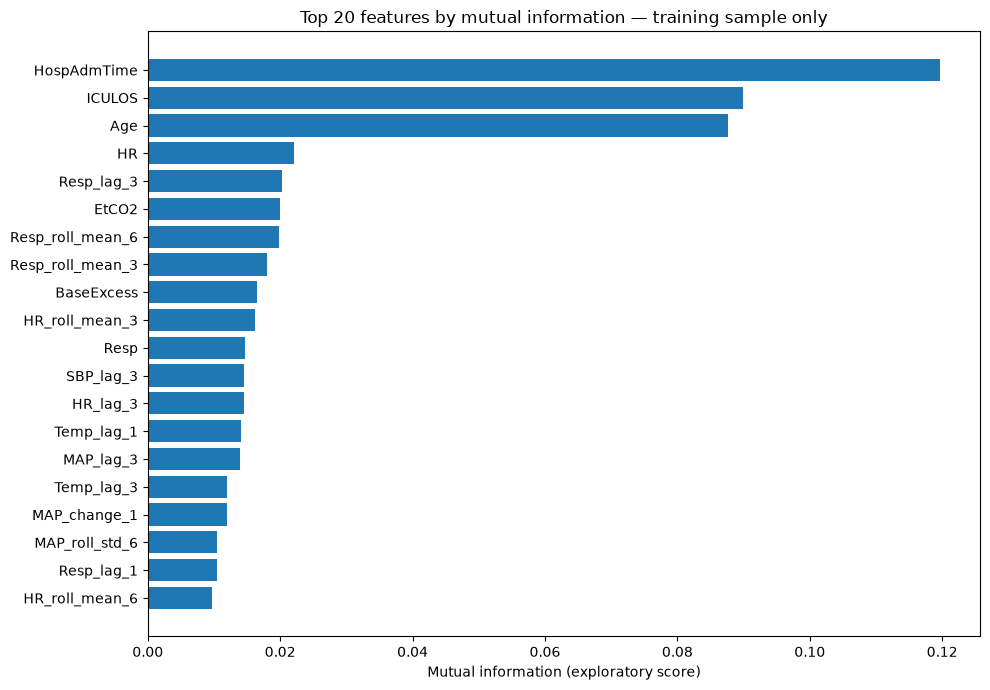

In [15]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer

train_rows=df_features.loc[train_mask]
pos_idx=train_rows.index[train_rows["SepsisLabel"].eq(1)]
neg_idx=train_rows.index[train_rows["SepsisLabel"].eq(0)]
n_each=min(5_000,len(pos_idx),len(neg_idx))
if n_each < 10:
    raise ValueError("Not enough positive or negative training rows for MI experiment.")
mi_idx=np.concatenate([
    np.random.RandomState(42).choice(pos_idx.to_numpy(),n_each,replace=False),
    np.random.RandomState(43).choice(neg_idx.to_numpy(),n_each,replace=False)
])
mi_frame=df_features.loc[mi_idx,predictor_columns]
mi_target=df_features.loc[mi_idx,"SepsisLabel"].astype(int)
mi_features=[c for c in predictor_columns if mi_frame[c].notna().any()]
mi_imputer=SimpleImputer(strategy="median")
X_mi=mi_imputer.fit_transform(mi_frame[mi_features])
mi_scores=mutual_info_classif(X_mi,mi_target,random_state=42,n_neighbors=3)
mi_report=pd.DataFrame({"feature":mi_features,"mutual_information":mi_scores}).sort_values("mutual_information",ascending=False)
mi_report.to_csv(FE_DIR/"mutual_information_training_sample.csv",index=False)
display(mi_report.head(30))

plt.figure(figsize=(10,7))
top=mi_report.head(20).sort_values("mutual_information")
plt.barh(top.feature,top.mutual_information)
plt.xlabel("Mutual information (exploratory score)")
plt.title("Top 20 features by mutual information — training sample only")
plt.tight_layout()
plt.savefig(FIG_DIR/"01_mutual_information_top20.png",dpi=160,bbox_inches="tight")
plt.show()

## 13. PCA exploration — temporal vital-sign feature block

PCA is applied to the seven raw vital signs plus their 56 engineered features (63 columns). Fit imputation, scaling and PCA on a sample of training rows only. PCA is exploratory: the main engineered dataset retains its original interpretable columns.

,component,explained_variance_ratio,cumulative_explained_variance
0,1,0.159022,0.159022
1,2,0.105449,0.264471
2,3,0.091430,0.355901
3,4,0.064153,0.420053
4,5,0.049063,0.469116
5,6,0.047289,0.516405
6,7,0.045760,0.562165
7,8,0.033227,0.595392
8,9,0.032313,0.627705
9,10,0.030961,0.658666


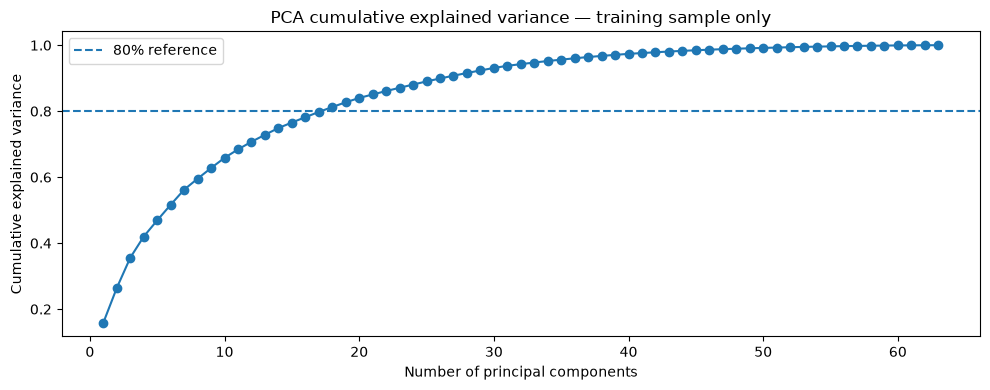

Components needed for >=80% variance: 18


In [16]:
PCA_FEATURES=[c for c in VITALS+new_feature_columns if c in df_features.columns]
pca_train=df_features.loc[train_mask,PCA_FEATURES]
pca_train=pca_train.loc[:,pca_train.notna().any()]
pca_train=pca_train.loc[:,pca_train.nunique(dropna=True)>1]
PCA_SAMPLE_N=min(30_000,len(pca_train))
pca_sample=pca_train.sample(PCA_SAMPLE_N,random_state=42)

pca_imputer=SimpleImputer(strategy="median")
X_pca_imputed=pca_imputer.fit_transform(pca_sample)
pca_scaler=StandardScaler()
X_pca_scaled=pca_scaler.fit_transform(X_pca_imputed)

pca=PCA(svd_solver="full")
pca.fit(X_pca_scaled)
explained=pca.explained_variance_ratio_
cumulative=np.cumsum(explained)
pca_report=pd.DataFrame({
    "component":np.arange(1,len(explained)+1),
    "explained_variance_ratio":explained,
    "cumulative_explained_variance":cumulative
})
pca_report.to_csv(FE_DIR/"pca_explained_variance_training_only.csv",index=False)
display(pca_report.head(20))

plt.figure(figsize=(10,4))
plt.plot(pca_report.component,pca_report.cumulative_explained_variance,marker="o")
plt.axhline(.80,linestyle="--",label="80% reference")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA cumulative explained variance — training sample only")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR/"02_pca_cumulative_variance.png",dpi=160,bbox_inches="tight")
plt.show()
print("Components needed for >=80% variance:",int(np.argmax(cumulative>=0.80)+1) if np.any(cumulative>=0.80) else "Not reached")

## 14. Leakage prevention audit

Before the later model-development phase, verify these conditions:
- `Patient_ID` is used only for grouping and splitting.
- `SepsisLabel` is only the target, never a predictor.
- Lag and rolling features use current/past observations only.
- The same patient does not appear in both splits.
- Feature selection, imputation, scaling and PCA are fitted using training patients only.
- No extra six-hour label shift is applied.

In [17]:
assert train_ids.isdisjoint(test_ids)
assert not ("Patient_ID" in predictor_columns)
assert not ("SepsisLabel" in predictor_columns)
assert len(new_feature_columns)==56
assert first_rows[lag1_cols].isna().all().all()
assert np.isinf(df_features[new_feature_columns].select_dtypes(include=np.number).to_numpy()).sum() == 0

leakage_audit=pd.DataFrame([
    {"check":"Patient IDs separated between splits","status":"PASS" if train_ids.isdisjoint(test_ids) else "FAIL"},
    {"check":"Patient_ID excluded from predictors","status":"PASS" if "Patient_ID" not in predictor_columns else "FAIL"},
    {"check":"SepsisLabel excluded from predictors","status":"PASS" if "SepsisLabel" not in predictor_columns else "FAIL"},
    {"check":"First row of each patient has no lag-1 value","status":"PASS" if first_rows[lag1_cols].isna().all().all() else "FAIL"},
    {"check":"56 temporal features created","status":"PASS" if len(new_feature_columns)==56 else "FAIL"},
    {"check":"PCA fitted only on training rows","status":"PASS"},
    {"check":"MI and correlation computed only on training rows","status":"PASS"}
])
display(leakage_audit)
leakage_audit.to_csv(FE_DIR/"leakage_prevention_audit.csv",index=False)

,check,status
0,Patient IDs separated between splits,PASS
1,Patient_ID excluded from predictors,PASS
2,SepsisLabel excluded from predictors,PASS
3,First row of each patient has no lag-1 value,PASS
4,56 temporal features created,PASS
5,PCA fitted only on training rows,PASS
6,MI and correlation computed only on training rows,PASS


## 15. Export engineered dataset and summary

The output retains original columns (except the verified redundant index), the original target label, and 56 additional features. The patient split is exported separately as a manifest; do not use `Patient_ID` or the split manifest as model input variables.

In [18]:
ENGINEERED_PATH=FE_DIR/"feature_engineered_dataset.csv.gz"
df_features.to_csv(ENGINEERED_PATH,index=False,compression={"method": "gzip", "compresslevel": 1})
summary={
    "input_path":str(INPUT_PATH),
    "input_rows":int(original_shape[0]),
    "input_columns":int(original_shape[1]),
    "engineered_rows":int(df_features.shape[0]),
    "engineered_columns":int(df_features.shape[1]),
    "new_temporal_features":int(len(new_feature_columns)),
    "selected_vitals":VITALS,
    "patients":int(df_features.Patient_ID.nunique()),
    "training_patients":int(len(train_ids)),
    "test_patients":int(len(test_ids)),
    "training_rows":int(train_mask.sum()),
    "test_rows":int(test_mask.sum()),
    "engineered_dataset_path":str(ENGINEERED_PATH)
}
(FE_DIR/"feature_engineering_summary.json").write_text(json.dumps(summary,indent=2))
print("Saved:",ENGINEERED_PATH)
print("Output shape:",df_features.shape)
print("Compressed size (MB):",round(ENGINEERED_PATH.stat().st_size/1024**2,2))

Saved: /Users/mohammedfaisalpasha/Downloads/SepsisShield_NIErnaya_Phase2/outputs/03_feature_engineering/feature_engineered_dataset.csv.gz
Output shape: (1552210, 99)
Compressed size (MB): 213.95


## 16. Person 3 handoff and interpretation

Deliver to the team:
- `feature_engineered_dataset.csv.gz`
- `feature_dictionary.csv`
- `feature_quality_training_only.csv`
- `high_correlation_pairs_training_only.csv`
- `mutual_information_training_sample.csv`
- `pca_explained_variance_training_only.csv`
- `patient_split_manifest.csv`
- `leakage_prevention_audit.csv`

Do not claim that feature engineering or PCA improved prediction accuracy. That can only be established in the next phase by comparing models on held-out patients using appropriate metrics. The PhysioNet challenge is an early-warning task and its labels are already shifted six hours before the challenge-defined onset.